# Why observed anomalies are harder to predict — diagnostics

Model **B** predicts the crop models' yield anomalies (SIMPLACE and torchcrop
separately) and model **C** predicts CyBench observed anomalies. Both use the
same MSWX season indices (`extremes.py`) and the same gradient boosting
(`attribution._model`). In the attribution notebook R²(C) ≈ 0.05 while
R²(B) ≈ 0.3. This notebook works out how much of that gap is real.

All targets share **one panel**: the unit-years that SIMPLACE, torchcrop and
CyBench all have in 2000–2021, with at least 10 seasons per unit. Every model
is scored on the same rows and the same folds.

**Skill** is `1 − SSE / Σy²`, measured against the trend-only forecast
(anomaly = 0). It is reported pooled over all held-out rows, and as the
mean ± sd over folds.

## 0. Setup and panel

In [1]:
import logging
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
import attribution as att
import diagnostics as dg
import extremes as ex
import stage_indices as si

from cropmodelling4eu.evaluation import production as prod
from cropmodelling4eu.evaluation.fullrun import load_runs
from cropmodelling4eu.evaluation.plots import EUROPE_PROJECTION, country_choropleth, save
from cropmodelling4eu.evaluation.regions import load_admin_polygons
from cropmodelling4eu.evaluation.style import use_style

logging.basicConfig(level=logging.WARNING, force=True)
PALETTE = use_style("light")
np.random.seed(dg.SEED)

RUN = prod.PRODUCTION_RUN_DIR
EXTREMES = RUN / "analysis" / "extremes"
OUT = Path(os.environ.get("DIAGNOSTICS_DIR", RUN / "analysis" / "diagnostics"))
FIGURES, TABLES = OUT / "figures", OUT / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

runs = load_runs(RUN / "simplace" / "simplace_europe.parquet",
                 RUN / "torchcrop" / "torchcrop_europe.parquet", years=att.COMMON_YEARS)
cell_to_adm = pd.read_parquet(prod.CALIBRATION_DIR / "cell_to_adm.parquet")
countries = sorted(cell_to_adm["adm_country"].dropna().unique())
reference = prod.load_reference(countries, att.COMMON_YEARS)
units = cell_to_adm.dropna(subset=["adm_id"]).drop_duplicates("adm_id")
unit_country = pd.Series(units["adm_country"].to_numpy(), index=units["adm_id"].astype("string"))

yields = att.unit_yields(runs, reference, cell_to_adm)
features = att.unit_extremes(pd.read_parquet(EXTREMES / "season_extremes.parquet"), cell_to_adm)
panel = (dg.build_panel(yields, features, unit_country)
         .merge(dg.unit_outputs(RUN, cell_to_adm, att.COMMON_YEARS), on=["adm_id", "year"], how="left"))
panel["country_code"] = panel["country"].astype("category").cat.codes
print(f"{len(panel)} unit-years, {panel['adm_id'].nunique()} units, "
      f"{panel['country'].nunique()} countries, {panel['year'].min()}-{panel['year'].max()}")

ERROR 1: PROJ: proj_create_from_database: Open of /home/muduchuru/miniforge3/envs/sdba/share/proj failed


14552 unit-years, 734 units, 20 countries, 2000-2021


## Step 1 — Anomaly consistency and leakage audit

**a. One anomaly definition.** Each target is a relative anomaly,
`100 · (y / trend − 1)`, against a per-unit trend. The same function
(`dg.anomalies`) and the same method are applied to SIMPLACE, torchcrop and
CyBench alike. The method (linear, quadratic or LOESS) is the only switch.

**b. References fitted in-fold.** Under leave-one-year-out, every fold refits
each unit's yield trend *and* its hazard climatology on the training years
only. The held-out season is then a genuine out-of-sample point for both. The
attribution notebook instead fitted both on all years (its *full-series*
references), and that variant is rerun here to measure the leakage.

**c. No year fixed effects.** No year means are removed. The season-wide shock
that every unit shares is exactly what the weather has to explain, so it stays
in both targets.

**d–f.** Three detrending methods are crossed with two CV schemes.
Leave-one-country-out tests transfer to unseen regions. A test country has no
training rows, so its own series defines its trend and climatology. That is a
target definition, not leakage: none of it reaches the fitted model.

In [2]:
audit = dg.audit_grid(panel)
audit.to_csv(TABLES / "step1_audit.csv", index=False)
(audit.assign(cell=lambda f: f.apply(
        lambda r: f"{r['R²']:.3f}  ({r['R² fold mean']:.2f} ± {r['R² fold sd']:.2f})", axis=1))
 .pivot(index=["cv", "detrending"], columns="target", values="cell")[list(dg.TARGETS.values())])

target                                                    B · SIMPLACE  \
cv                                    detrending                         
leave-one-country-out                 linear      0.262  (0.26 ± 0.24)   
                                      loess       0.258  (0.27 ± 0.21)   
                                      quadratic   0.259  (0.27 ± 0.22)   
leave-one-year-out (full-series refs) linear      0.234  (0.17 ± 0.18)   
                                      loess       0.222  (0.16 ± 0.19)   
                                      quadratic   0.218  (0.16 ± 0.19)   
leave-one-year-out (in-fold refs)     linear      0.268  (0.22 ± 0.16)   
                                      loess       0.246  (0.21 ± 0.15)   
                                      quadratic   0.209  (0.18 ± 0.15)   

target                                                   B · torchcrop  \
cv                                    detrending                         
leave-one-country-out                 linear      0.268  (0.20 ± 0.49)   
                                      loess       0.263  (0.21 ± 0.45)   
                                      quadratic   0.278  (0.22 ± 0.44)   
leave-one-year-out (full-series refs) linear      0.327  (0.22 ± 0.38)   
                                      loess       0.316  (0.22 ± 0.29)   
                                      quadratic   0.308  (0.20 ± 0.34)   
leave-one-year-out (in-fold refs)     linear      0.345  (0.26 ± 0.33)   
                                      loess       0.323  (0.26 ± 0.23)   
                                      quadratic   0.278  (0.25 ± 0.24)   

target                                                     C · observed  
cv                                    detrending                         
leave-one-country-out                 linear       0.072  (0.15 ± 0.14)  
                                      loess        0.067  (0.16 ± 0.15)  
                                      quadratic    0.083  (0.16 ± 0.15)  
leave-one-year-out (full-series refs) linear      0.016  (-0.00 ± 0.12)  
                                      loess       0.024  (-0.00 ± 0.13)  
                                      quadratic    0.025  (0.00 ± 0.11)  
leave-one-year-out (in-fold refs)     linear       0.033  (0.01 ± 0.10)  
                                      loess        0.045  (0.03 ± 0.10)  
                                      quadratic    0.042  (0.03 ± 0.09)

Pooled R² in each cell; the fold mean ± sd is in brackets. Below: the same
scores as bars, and the leakage, i.e. full-series minus in-fold references
under leave-one-year-out.

refs                       full  in_fold  leakage (full − in-fold)
target        detrending                                          
B · SIMPLACE  linear      0.234    0.268                    -0.035
              loess       0.222    0.246                    -0.024
              quadratic   0.218    0.209                     0.009
B · torchcrop linear      0.327    0.345                    -0.017
              loess       0.316    0.323                    -0.007
              quadratic   0.308    0.278                     0.030
C · observed  linear      0.016    0.033                    -0.017
              loess       0.024    0.045                    -0.021
              quadratic   0.025    0.042                    -0.017

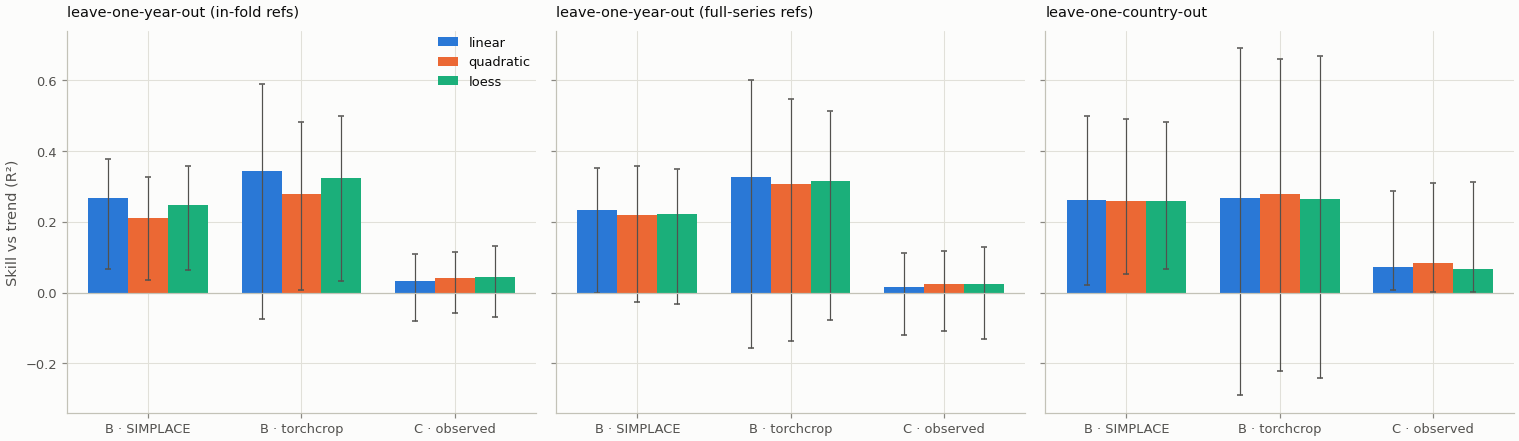

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.2), sharey=True)
colours = dict(zip(dg.DETRENDS, (PALETTE["series_1"], PALETTE["series_2"], PALETTE["series_3"])))
for ax, (cv, block) in zip(axes, audit.groupby("cv", sort=False)):
    x = np.arange(len(dg.TARGETS))
    for i, method in enumerate(dg.DETRENDS):
        b = block[block["detrending"] == method].set_index("target").loc[list(dg.TARGETS.values())]
        ax.bar(x + (i - 1) * 0.26, b["R²"], 0.26, color=colours[method], label=method)
        ax.errorbar(x + (i - 1) * 0.26, b["R² fold mean"], yerr=b["R² fold sd"], fmt="none",
                    ecolor=PALETTE["secondary"], elinewidth=0.8, capsize=2)
    ax.set_xticks(x, list(dg.TARGETS.values()))
    ax.set_title(cv, fontsize=plt.rcParams["font.size"])
    ax.axhline(0, color=PALETTE["baseline"], lw=0.8)
axes[0].set_ylabel("Skill vs trend (R²)")
axes[0].legend(frameon=False)
fig.tight_layout()
save(fig, "step1_audit", FIGURES)

loyo = audit[audit["cv"].str.startswith("leave-one-year")]
leak = (loyo.assign(refs=np.where(loyo["cv"].str.contains("full-series"), "full", "in_fold"))
        .pivot_table(index=["target", "detrending"], columns="refs", values="R²"))
leak["leakage (full − in-fold)"] = leak["full"] - leak["in_fold"]
leak.round(3)

**e. Suspect CyBench series.** Each unit's raw observed series (2000–2021) is
checked for three things:
* a robust outlier: |z| > 4 against the MAD of its linear-trend residuals;
* a level step: the most significant before/after split in those residuals,
  Bonferroni-corrected, with p < 0.001;
* a gap: missing years inside the series.

An outlier is **not** assumed to be an error. 2003 and 2018 were real
seasons, and those are the years the weather model most needs to explain. So
R²(C) is reported two ways: excluding step and gap units only, and excluding
every flag.

In [4]:
flags = dg.flag_series(yields)
flags.to_csv(TABLES / "step1_cybench_flags.csv", index=False)
display(flags[["outlier", "step", "gap", "flagged"]].sum().rename("units").to_frame()
        .assign(share_pct=lambda f: (100 * f["units"] / len(flags)).round(1)))
display(flags["outlier_year"].where(flags["outlier"]).value_counts().head(8)
        .rename("units whose outlier falls in this year").to_frame())

subsets = {
    "all units": panel,
    "drop step + gap": panel[~panel["adm_id"].isin(flags.loc[flags["step"] | flags["gap"], "adm_id"])],
    "drop every flag": panel[~panel["adm_id"].isin(flags.loc[flags["flagged"], "adm_id"])],
}
best = audit[audit["cv"].str.contains("in-fold") & (audit["target"] == dg.TARGETS["observed"])
             ].sort_values("R²").iloc[-1]["detrending"]
rows = []
for name, sub in subsets.items():
    sub = sub.reset_index(drop=True)
    for target in dg.TARGETS:
        s = dg.cross_validate(sub, target, best, "year", True).scores()
        rows.append({"subset": name, "units": sub["adm_id"].nunique(), "target": dg.TARGETS[target],
                     "R²": s["R²"], "R² fold mean ± sd": f"{s['R² fold mean']:.2f} ± {s['R² fold sd']:.2f}"})
flag_scores = pd.DataFrame(rows)
flag_scores.to_csv(TABLES / "step1_flag_scores.csv", index=False)
print(f"detrending: {best} (best in-fold observed); CV: leave-one-year-out, in-fold references")
flag_scores.pivot(index=["subset", "units"], columns="target", values="R²").round(3)

,units,share_pct
outlier,97,12.7
step,2,0.3
gap,200,26.1
flagged,269,35.1


,units whose outlier falls in this year
outlier_year,
2016.0,29
2018.0,10
2003.0,8
2004.0,6
2012.0,5
2017.0,5
2011.0,5
2020.0,4


detrending: loess (best in-fold observed); CV: leave-one-year-out, in-fold references


,target,B · SIMPLACE,B · torchcrop,C · observed
subset,units,,,
all units,734,0.246,0.323,0.045
drop every flag,478,0.201,0.296,0.040
drop step + gap,542,0.203,0.293,0.029


## Step 2 — Baselines

Every row below is scored on the same panel, with the same anomalies, the same
folds and the same skill measure. Detrending is LOESS, the best method for C
in Step 1, and references are refitted inside every fold.

| Baseline | What it measures |
|---|---|
| B · ML → crop-model anomaly | Emulation skill: how much of the model's own variability the indices capture |
| Crop model vs observed, no ML | Process-model skill. *Rescaled* fits `obs = a + b·sim` on the training rows, which separates pattern from amplitude |
| C · ML → observed anomaly | Data-driven skill |
| Residual · ML → (observed − simulated) | Signal the crop model misses. *R² on observed* scores `sim + predicted residual` against the observations |
| Hybrid C | C plus each crop model's in-fold anomalies of yield, biomass, LAI and torchcrop's stress factors |

The two CV schemes:
* **leave-one-year-out** (22 folds);
* **country × year blocks** (5 × 5): a test block's countries *and* years are both
  absent from training, which closes the leak found in Step 1.

In [5]:
folds = {"leave-one-year-out": dg.loyo_folds(panel),
         "country × year blocks": dg.blocked_folds(panel)}
step2 = {scheme: dg.run_specs(panel, dg.STEP2_SPECS, f, scheme) for scheme, f in folds.items()}

table = pd.DataFrame([
    {"scheme": scheme, "baseline": name, **res.scores()}
    for scheme, results in step2.items() for name, res in results.items()
])
table.to_csv(TABLES / "step2_baselines.csv", index=False)
(table.assign(**{"R² (fold mean ± sd)": lambda f: f.apply(
        lambda r: f"{r['R²']:.3f}  ({r['R² fold mean']:.2f} ± {r['R² fold sd']:.2f})", axis=1)})
 .pivot(index="baseline", columns="scheme", values="R² (fold mean ± sd)")
 .reindex([s.name for s in dg.STEP2_SPECS]))

ERROR 1: PROJ: proj_create_from_database: Open of /home/muduchuru/miniforge3/envs/sdba/share/proj failed
ERROR 1: PROJ: proj_create_from_database: Open of /home/muduchuru/miniforge3/envs/sdba/share/proj failed
ERROR 1: PROJ: proj_create_from_database: Open of /home/muduchuru/miniforge3/envs/sdba/share/proj failed
ERROR 1: PROJ: proj_create_from_database: Open of /home/muduchuru/miniforge3/envs/sdba/share/proj failed
ERROR 1: PROJ: proj_create_from_database: Open of /home/muduchuru/miniforge3/envs/sdba/share/proj failed
ERROR 1: PROJ: proj_create_from_database: Open of /home/muduchuru/miniforge3/envs/sdba/share/proj failed
ERROR 1: PROJ: proj_create_from_database: Open of /home/muduchuru/miniforge3/envs/sdba/share/proj failed
ERROR 1: PROJ: proj_create_from_database: Open of /home/muduchuru/miniforge3/envs/sdba/share/proj failed
ERROR 1: PROJ: proj_create_from_database: Open of /home/muduchuru/miniforge3/envs/sdba/share/proj failed
ERROR 1: PROJ: proj_create_from_database: Open of /home

scheme,country × year blocks,leave-one-year-out
baseline,,
B · SIMPLACE (ML),0.157 (0.14 ± 0.21),0.246 (0.21 ± 0.15)
B · torchcrop (ML),0.179 (0.08 ± 0.52),0.323 (0.26 ± 0.23)
SIMPLACE vs observed (no ML),-0.296 (-0.64 ± 0.63),-0.323 (-0.60 ± 0.55)
torchcrop vs observed (no ML),-0.139 (-0.35 ± 0.55),-0.124 (-0.23 ± 0.30)
SIMPLACE vs observed (rescaled),0.078 (0.05 ± 0.14),0.110 (0.09 ± 0.13)
torchcrop vs observed (rescaled),0.057 (0.03 ± 0.18),0.098 (0.09 ± 0.10)
C · observed (ML),0.015 (-0.01 ± 0.16),0.045 (0.03 ± 0.10)
residual · obs − SIMPLACE (ML),0.047 (0.07 ± 0.09),0.103 (0.11 ± 0.11)
residual · obs − torchcrop (ML),0.016 (0.02 ± 0.16),0.064 (0.07 ± 0.08)


Correlation, RMSE and, for the residual models, the skill of `sim + predicted residual` on the observations:

In [6]:
(table.set_index(["scheme", "baseline"])[["r", "RMSE (%)", "R² on observed", "rows"]]
 .round(3).unstack("scheme").reindex([s.name for s in dg.STEP2_SPECS]))

r  \
scheme                                country × year blocks   
baseline                                                      
B · SIMPLACE (ML)                                     0.399   
B · torchcrop (ML)                                    0.431   
SIMPLACE vs observed (no ML)                          0.300   
torchcrop vs observed (no ML)                         0.274   
SIMPLACE vs observed (rescaled)                       0.281   
torchcrop vs observed (rescaled)                      0.249   
C · observed (ML)                                     0.152   
residual · obs − SIMPLACE (ML)                        0.225   
residual · obs − torchcrop (ML)                       0.163   
hybrid C · hazards + crop models (ML)                 0.285   
crop-model outputs only (ML)                          0.273   

                                                          \
scheme                                leave-one-year-out   
baseline                                                   
B · SIMPLACE (ML)                                  0.499   
B · torchcrop (ML)                                 0.578   
SIMPLACE vs observed (no ML)                       0.337   
torchcrop vs observed (no ML)                      0.319   
SIMPLACE vs observed (rescaled)                    0.332   
torchcrop vs observed (rescaled)                   0.314   
C · observed (ML)                                  0.218   
residual · obs − SIMPLACE (ML)                     0.321   
residual · obs − torchcrop (ML)                    0.253   
hybrid C · hazards + crop models (ML)              0.397   
crop-model outputs only (ML)                       0.371   

                                                   RMSE (%)  \
scheme                                country × year blocks   
baseline                                                      
B · SIMPLACE (ML)                                    16.189   
B · torchcrop (ML)                                   12.768   
SIMPLACE vs observed (no ML)                         21.798   
torchcrop vs observed (no ML)                        20.430   
SIMPLACE vs observed (rescaled)                      18.382   
torchcrop vs observed (rescaled)                     18.590   
C · observed (ML)                                    18.999   
residual · obs − SIMPLACE (ML)                       21.280   
residual · obs − torchcrop (ML)                      20.263   
hybrid C · hazards + crop models (ML)                18.394   
crop-model outputs only (ML)                         18.467   

                                                          \
scheme                                leave-one-year-out   
baseline                                                   
B · SIMPLACE (ML)                                 14.828   
B · torchcrop (ML)                                11.178   
SIMPLACE vs observed (no ML)                      19.678   
torchcrop vs observed (no ML)                     18.137   
SIMPLACE vs observed (rescaled)                   16.142   
torchcrop vs observed (rescaled)                  16.245   
C · observed (ML)                                 16.717   
residual · obs − SIMPLACE (ML)                    18.639   
residual · obs − torchcrop (ML)                   17.551   
hybrid C · hazards + crop models (ML)             15.705   
crop-model outputs only (ML)                      15.891   

                                             R² on observed  \
scheme                                country × year blocks   
baseline                                                      
B · SIMPLACE (ML)                                       NaN   
B · torchcrop (ML)                                      NaN   
SIMPLACE vs observed (no ML)                            NaN   
torchcrop vs observed (no ML)                           NaN   
SIMPLACE vs observed (rescaled)                         NaN   
torchcrop vs observed (rescaled)                        NaN   
C · observed (ML)                          

### Reading the pattern

The brief's decision rule compares C with each crop model scored directly
against the observations (the better of raw and rescaled):

* C ≈ crop model, both low → mostly non-weather noise;
* C > crop model → the indices capture effects the crop model misses;
* C < crop model → C under-uses the weather signal, and its features need work.

In [7]:
def r2(scheme, name):
    return float(table.loc[(table["scheme"] == scheme) & (table["baseline"] == name), "R²"].iloc[0])

for scheme in step2:
    c = r2(scheme, "C · observed (ML)")
    hybrid = r2(scheme, "hybrid C · hazards + crop models (ML)")
    print(f"{scheme}:  R²(C) = {c:.3f},  R²(hybrid) = {hybrid:.3f}")
    for m, label in (("simplace", "SIMPLACE"), ("torchcrop", "torchcrop")):
        process = max(r2(scheme, f"{label} vs observed (no ML)"),
                      r2(scheme, f"{label} vs observed (rescaled)"))
        emul = r2(scheme, f"B · {label} (ML)")
        if max(c, process) < 0.1 and abs(c - process) < 0.03:
            verdict = "C ≈ process model, both low -> mostly non-weather noise"
        elif c > process:
            verdict = "C > process model -> indices capture effects the crop model misses"
        else:
            verdict = "C < process model -> C under-uses the weather signal"
        print(f"   {label:9s} R²(B) = {emul:.3f}  process vs obs = {process:.3f}   {verdict}")

leave-one-year-out:  R²(C) = 0.045,  R²(hybrid) = 0.157
   SIMPLACE  R²(B) = 0.246  process vs obs = 0.110   C < process model -> C under-uses the weather signal
   torchcrop R²(B) = 0.323  process vs obs = 0.098   C < process model -> C under-uses the weather signal
country × year blocks:  R²(C) = 0.015,  R²(hybrid) = 0.077
   SIMPLACE  R²(B) = 0.157  process vs obs = 0.078   C < process model -> C under-uses the weather signal
   torchcrop R²(B) = 0.179  process vs obs = 0.057   C < process model -> C under-uses the weather signal


### Grouped permutation importance

Each bar is the skill lost when a group's columns are permuted together on the
held-out rows, as a fraction of `Σy²`, for country × year blocks. *Hybrid* is
the crop-model outputs.

,context,heat,hybrid,other,water deficit,wet
B · SIMPLACE (ML),0.033,-0.003,NaN,-0.000,0.332,0.004
B · torchcrop (ML),0.041,0.082,NaN,0.013,0.279,0.005
C · observed (ML),0.009,0.010,NaN,0.023,0.018,0.002
residual · obs − torchcrop (ML),0.008,0.000,NaN,0.015,0.054,0.005
hybrid C · hazards + crop models (ML),-0.000,0.003,0.156,0.009,0.001,0.000


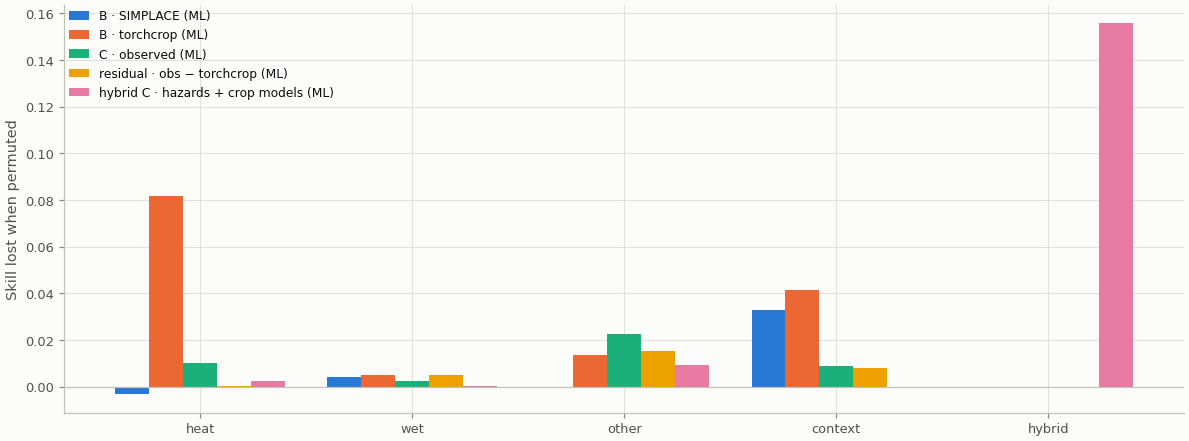

In [8]:
blocked = step2["country × year blocks"]
show = ["B · SIMPLACE (ML)", "B · torchcrop (ML)", "C · observed (ML)",
        "residual · obs − torchcrop (ML)", "hybrid C · hazards + crop models (ML)"]
imp = pd.DataFrame({name: blocked[name].importance() for name in show}).T
imp.to_csv(TABLES / "step2_grouped_importance.csv")
fig, ax = plt.subplots(figsize=(11.0, 4.2))
groups = [g for g in ("heat", "drought", "wet", "other", "context", "hybrid") if g in imp]
width = 0.8 / len(show)
for i, name in enumerate(show):
    ax.bar(np.arange(len(groups)) + i * width, imp.loc[name, groups].fillna(0), width, label=name)
ax.set_xticks(np.arange(len(groups)) + 0.4 - width / 2, groups)
ax.axhline(0, color=PALETTE["baseline"], lw=0.8)
ax.set_ylabel("Skill lost when permuted")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
save(fig, "step2_importance", FIGURES)
imp.round(3)

## Step 3 — Feature improvements

Each ablation is run on the five targets: C, both B models and both
residuals. The folds, anomalies and model (pooled gradient boosting) are the
same throughout, and no permutation is done here. The stage indices
(`stage_indices.py`) summarise 12 daily variables in five stages (autumn,
winter, stem elongation, flowering, grain fill). VPD comes from `RelHumCalc`.
A 150 mm bucket gives a soil-moisture proxy and waterlogging days. Water
balance and soil moisture enter as per-unit z-scores, which are SPEI-like.

| Ablation | Brief item | Features |
|---|---|---|
| S0 | — | the 12 season indices of the attribution notebook |
| S1 | c | + stage-wise extremes: heat at anthesis, stem-elongation dry spell, frost after green-up, warm autumn, wet days and waterlogging, winterkill |
| S2 | e | + VPD, SPEI-like water balance, soil moisture, stem radiation |
| S3 | d | + six ordered sequences (products of signed in-fold z-scores) |
| FULL · calendar / phenology / simulated | a | all 61 stage indices in fixed calendar months, the cell's climatological phenology, or that season's own simulated phenology |
| S3 · cropland-weighted | b | S3 with every cell weighted by its PROBA-V cropland area, for the indices *and* the simulated yields |
| FULL · stage order shuffled | d | each row's five stages permuted, three seeds — the timing permutation test |

In [9]:
STAGE_DIR = OUT / "stage_indices"
weights = si.cropland_area()
stage_cells = {v: pd.read_parquet(STAGE_DIR / f"stage_indices_{v}.parquet") for v in si.VARIANTS}
stage_units = {v: si.unit_means(f, cell_to_adm, si.COLUMNS) for v, f in stage_cells.items()}
panels = {v: dg.with_stage(panel, f) for v, f in stage_units.items()}

weighted = dg.with_stage(panel, si.unit_means(stage_cells["phenology"], cell_to_adm, si.COLUMNS, weights))
cell_extremes = pd.read_parquet(EXTREMES / "season_extremes.parquet")
cell_extremes = cell_extremes[cell_extremes["year"].between(*att.COMMON_YEARS)]
v1w = si.unit_means(cell_extremes, cell_to_adm, list(ex.FEATURES), weights)
weighted = weighted.drop(columns=list(ex.FEATURES)).merge(v1w, on=["adm_id", "year"], how="left")
for m in dg.MODELS:
    yw = si.unit_means(runs[m][["SimplaceID", "year", "yield_t_ha"]], cell_to_adm, ["yield_t_ha"], weights)
    weighted = weighted.drop(columns=m).merge(yw.rename(columns={"yield_t_ha": m}), on=["adm_id", "year"], how="left")
weighted = weighted.set_index(["adm_id", "year"]).loc[pd.MultiIndex.from_frame(panel[["adm_id", "year"]])].reset_index()
print(f"cropland weights for {weights.gt(0).sum()} cells; weighted panel rows {len(weighted)} = {len(panel)}")

phen = panels["phenology"]
ablation_runs = {
    "S0 · 12 season indices": (phen, dg.FEATURE_SETS["S0 · 12 season indices"]),
    "S1 · + stage extremes": (phen, dg.FEATURE_SETS["S1 · + stage extremes"]),
    "S2 · + VPD, SPEI, soil moisture": (phen, dg.FEATURE_SETS["S2 · + VPD, SPEI, soil moisture"]),
    "S3 · + sequences": (phen, dg.FEATURE_SETS["S3 · + sequences"]),
    "S3 · cropland-weighted": (weighted, dg.FEATURE_SETS["S3 · + sequences"]),
    "FULL · calendar months": (panels["calendar"], dg.FEATURE_SETS["FULL · stage × variable"]),
    "FULL · climatological phenology": (phen, dg.FEATURE_SETS["FULL · stage × variable"]),
    "FULL · simulated phenology": (panels["simulated"], dg.FEATURE_SETS["FULL · stage × variable"]),
    **{f"FULL · stage order shuffled (seed {k})": (dg.shuffle_stages(phen, k), dg.FEATURE_SETS["FULL · stage × variable"])
       for k in (1, 2, 3)},
}
ablations = {
    name: {scheme: dg.run_specs(pnl, dg.ablation_specs(feats), folds[scheme], scheme, n_repeats=0)
           for scheme in folds}
    for name, (pnl, feats) in ablation_runs.items()
}
ablation_table = pd.DataFrame([
    {"ablation": name, "scheme": scheme, "target": label, **res.scores()}
    for name, by_scheme in ablations.items() for scheme, results in by_scheme.items()
    for label, res in results.items()
])
ablation_table.to_csv(TABLES / "step3_ablations.csv", index=False)
(ablation_table.assign(cell=lambda f: f.apply(
        lambda r: f"{r['R²']:.3f} ({r['R² fold mean']:.2f}±{r['R² fold sd']:.2f})", axis=1))
 .pivot(index=["scheme", "ablation"], columns="target", values="cell")
 .reindex(columns=list(dg.ABLATION_TARGETS))
 .reindex(pd.MultiIndex.from_product([list(folds), list(ablation_runs)]), axis=0))

cropland weights for 70705 cells; weighted panel rows 14552 = 14552


target                                                                        C  \
leave-one-year-out    S0 · 12 season indices                  0.045 (0.03±0.10)   
                      S1 · + stage extremes                   0.029 (0.02±0.10)   
                      S2 · + VPD, SPEI, soil moisture         0.098 (0.08±0.08)   
                      S3 · + sequences                        0.106 (0.09±0.09)   
                      S3 · cropland-weighted                  0.107 (0.10±0.08)   
                      FULL · calendar months                  0.115 (0.11±0.06)   
                      FULL · climatological phenology         0.115 (0.09±0.11)   
                      FULL · simulated phenology              0.097 (0.08±0.09)   
                      FULL · stage order shuffled (seed 1)    0.055 (0.04±0.08)   
                      FULL · stage order shuffled (seed 2)    0.051 (0.04±0.08)   
                      FULL · stage order shuffled (seed 3)    0.055 (0.05±0.07)   
country × year blocks S0 · 12 season indices                 0.015 (-0.01±0.16)   
                      S1 · + stage extremes                 -0.001 (-0.04±0.20)   
                      S2 · + VPD, SPEI, soil moisture         0.044 (0.04±0.14)   
                      S3 · + sequences                        0.047 (0.05±0.15)   
                      S3 · cropland-weighted                  0.045 (0.05±0.16)   
                      FULL · calendar months                  0.050 (0.06±0.10)   
                      FULL · climatological phenology         0.058 (0.06±0.17)   
                      FULL · simulated phenology              0.057 (0.05±0.16)   
                      FULL · stage order shuffled (seed 1)    0.021 (0.01±0.10)   
                      FULL · stage order shuffled (seed 2)    0.022 (0.01±0.10)   
                      FULL · stage order shuffled (seed 3)    0.019 (0.00±0.11)   

target                                                           B · SIMPLACE  \
leave-one-year-out    S0 · 12 season indices                0.246 (0.21±0.15)   
                      S1 · + stage extremes                 0.253 (0.23±0.13)   
                      S2 · + VPD, SPEI, soil moisture       0.426 (0.37±0.19)   
                      S3 · + sequences                      0.422 (0.37±0.20)   
                      S3 · cropland-weighted                0.427 (0.37±0.21)   
                      FULL · calendar months                0.411 (0.37±0.17)   
                      FULL · climatological phenology       0.443 (0.39±0.18)   
                      FULL · simulated phenology            0.444 (0.39±0.19)   
                      FULL · stage order shuffled (seed 1)  0.300 (0.28±0.13)   
                      FULL · stage order shuffled (seed 2)  0.299 (0.28±0.13)   
                      FULL · stage order shuffled (seed 3)  0.305 (0.28±0.14)   
country × year blocks S0 · 12 season indices                0.157 (0.14±0.21)   
                      S1 · + stage extremes                 0.155 (0.15±0.21)   
                      S2 · + VPD, SPEI, soil moisture       0.305 (0.32±0.16)   
                      S3 · + sequences                      0.296 (0.31±0.17)   
                      S3 · cropland-weighted                0.312 (0.33±0.16)   
                      FULL · calendar months                0.319 (0.33±0.12)   
                      FULL · climatological phenology       0.315 (0.33±0.16)   
                      FULL · simulated phenology            0.304 (0.32±0.19)   
                      FULL · stage order shuffled (seed 1)  0.187 (0.20±0.19)   
                      FULL · stage order shuffled (seed 2)  0.190 (0.21±0.19)   
                      FULL · stage order shuffled (seed 3)  0.185 (0.20±0.20)   

target                                                           B · torchcrop  \
leave-one-year-out    S0 · 12 season indices                 0.323 (0.26±0.23)   
                      S1 · + stage extremes                  0

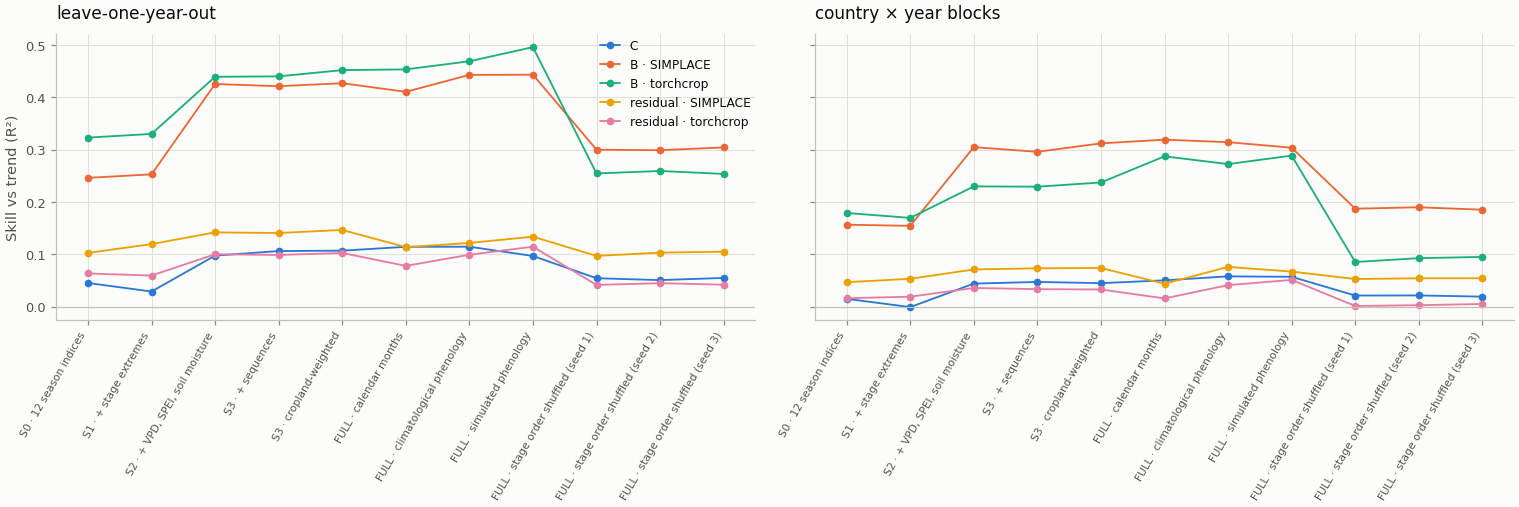

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14.0, 4.8), sharey=True)
order = list(ablation_runs)
for ax, scheme in zip(axes, folds):
    block = ablation_table[ablation_table["scheme"] == scheme]
    for i, target in enumerate(dg.ABLATION_TARGETS):
        vals = block[block["target"] == target].set_index("ablation").reindex(order)["R²"]
        ax.plot(range(len(order)), vals, marker="o", ms=4, lw=1.2, label=target,
                color=PALETTE[f"series_{i + 1}"])
    ax.set_xticks(range(len(order)), order, rotation=60, ha="right", fontsize=7)
    ax.set_title(scheme)
    ax.axhline(0, color=PALETTE["baseline"], lw=0.8)
axes[0].set_ylabel("Skill vs trend (R²)")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
save(fig, "step3_ablations", FIGURES);

**The stage-order permutation test.** The correctly timed FULL set is compared
with the three shuffled copies. If timing carries information, shuffling
costs skill. The *z* is the drop divided by the spread across shuffle seeds.

In [11]:
rows = []
for scheme in folds:
    b = ablation_table[ablation_table["scheme"] == scheme]
    for target in dg.ABLATION_TARGETS:
        t = b[b["target"] == target].set_index("ablation")["R²"]
        shuffled = t[[n for n in t.index if "shuffled" in n]]
        drop = t["FULL · climatological phenology"] - shuffled.mean()
        rows.append({"scheme": scheme, "target": target, "R² timed": t["FULL · climatological phenology"],
                     "R² shuffled (mean of 3)": shuffled.mean(), "drop": drop,
                     "z": drop / shuffled.std() if shuffled.std() > 0 else np.nan})
timing = pd.DataFrame(rows)
timing.to_csv(TABLES / "step3_stage_shuffle.csv", index=False)
timing.round(3)

,scheme,target,R² timed,R² shuffled (mean of 3),drop,z
0,leave-one-year-out,C,0.115,0.054,0.061,26.792
1,leave-one-year-out,B · SIMPLACE,0.443,0.301,0.142,50.247
2,leave-one-year-out,B · torchcrop,0.469,0.256,0.213,69.848
3,leave-one-year-out,residual · SIMPLACE,0.122,0.102,0.020,4.724
4,leave-one-year-out,residual · torchcrop,0.099,0.043,0.057,31.077
5,country × year blocks,C,0.058,0.021,0.037,29.493
6,country × year blocks,B · SIMPLACE,0.315,0.188,0.127,54.189
7,country × year blocks,B · torchcrop,0.273,0.091,0.182,35.803
8,country × year blocks,residual · SIMPLACE,0.076,0.054,0.022,26.624
9,country × year blocks,residual · torchcrop,0.041,0.003,0.038,19.656


## Step 4 — Model structure

Five structures are compared on the best observed feature set from Step 3,
with folds and anomalies unchanged. Each is fitted to C and to the hybrid C:

* **pooled GBM**: the model used so far;
* **GBM + country**: the country as a categorical feature, a region effect that
  lets the response differ by country;
* **per-country GBM**: a separate model for every country with ≥ 400 training
  rows, and the pooled model otherwise. Under country × year blocks every test
  country is unseen, so this falls back to pooled;
* **monotonic GBM**: heat, frost, winterkill and dry spells may only lower
  yield, and soil moisture and the crop models' anomalies may only raise it;
* **ridge**: linear, standardised, with α chosen in-fold. This is the
  small-sample baseline.

In [12]:
c_loyo = ablation_table[(ablation_table["scheme"] == "leave-one-year-out") & (ablation_table["target"] == "C")
                        & ~ablation_table["ablation"].str.contains("shuffled|weighted")]
best_name = c_loyo.sort_values("R²").iloc[-1]["ablation"]
best_panel, best_features = ablation_runs[best_name]
print(f"best observed feature set (leave-one-year-out): {best_name}  ({len(best_features)} features)")

STRUCTURES = {"pooled GBM": "gbm", "GBM + country": "gbm_country", "per-country GBM": "per_country",
              "monotonic GBM": "monotonic", "ridge": "ridge"}
structure_specs = [s for label, kind in STRUCTURES.items() for s in (
    dg.Spec(f"C · {label}", "observed", best_features, model=kind),
    dg.Spec(f"hybrid C · {label}", "observed", best_features, hybrid=True, model=kind))]
structures = {scheme: dg.run_specs(best_panel, structure_specs, folds[scheme], scheme, n_repeats=0)
              for scheme in folds}
structure_table = pd.DataFrame([{"scheme": scheme, "model": name, **r.scores()}
                                for scheme, res in structures.items() for name, r in res.items()])
structure_table.to_csv(TABLES / "step4_structures.csv", index=False)
(structure_table.assign(cell=lambda f: f.apply(
        lambda r: f"{r['R²']:.3f} ({r['R² fold mean']:.2f}±{r['R² fold sd']:.2f})", axis=1))
 .pivot(index="model", columns="scheme", values="cell").reindex([s.name for s in structure_specs]))

best observed feature set (leave-one-year-out): FULL · climatological phenology  (61 features)


scheme,country × year blocks,leave-one-year-out
model,,
C · pooled GBM,0.058 (0.06±0.17),0.115 (0.09±0.11)
hybrid C · pooled GBM,0.097 (0.11±0.18),0.170 (0.15±0.12)
C · GBM + country,0.057 (0.07±0.13),0.131 (0.11±0.09)
hybrid C · GBM + country,0.094 (0.11±0.16),0.183 (0.17±0.12)
C · per-country GBM,0.058 (0.06±0.17),0.074 (0.07±0.08)
hybrid C · per-country GBM,0.097 (0.11±0.18),0.116 (0.11±0.12)
C · monotonic GBM,0.057 (0.05±0.18),0.118 (0.09±0.12)
hybrid C · monotonic GBM,0.098 (0.10±0.17),0.171 (0.15±0.13)
C · ridge,0.051 (0.03±0.20),0.111 (0.10±0.13)


## Final run — grouped importance on the best setup

All six models are refitted on the best feature set, with grouped permutation:
three repeats on every held-out fold. Groups are heat, water deficit, wet,
VPD, other weather, sequence, the climate context, and hybrid (crop-model
outputs).

best structure for C: GBM + country


heat  water deficit    wet  \
scheme                model                                               
leave-one-year-out    B · SIMPLACE          0.041          0.327  0.035   
                      B · torchcrop         0.052          0.366  0.045   
                      C · observed          0.001          0.046  0.017   
                      residual · SIMPLACE   0.012          0.144  0.007   
                      residual · torchcrop  0.014          0.119  0.005   
                      hybrid C              0.001          0.014  0.009   
country × year blocks B · SIMPLACE          0.013          0.301  0.032   
                      B · torchcrop         0.030          0.294  0.045   
                      C · observed          0.004          0.028  0.011   
                      residual · SIMPLACE   0.008          0.102  0.006   
                      residual · torchcrop  0.006          0.079  0.007   
                      hybrid C             -0.001          0.013  0.004   

                                              VPD  other  context  region  \
scheme                model                                                 
leave-one-year-out    B · SIMPLACE          0.057  0.026    0.061     NaN   
                      B · torchcrop         0.050  0.046    0.082     NaN   
                      C · observed          0.033  0.020    0.001   0.029   
                      residual · SIMPLACE   0.002  0.007    0.018     NaN   
                      residual · torchcrop  0.007  0.012    0.031     NaN   
                      hybrid C              0.007  0.004    0.001   0.020   
country × year blocks B · SIMPLACE          0.044  0.062    0.016     NaN   
                      B · torchcrop         0.023  0.071    0.025     NaN   
                      C · observed          0.019  0.033    0.000   0.000   
                      residual · SIMPLACE   0.005  0.019    0.005     NaN   
                      residual · torchcrop  0.004  0.019    0.007     NaN   
                      hybrid C              0.004  0.013   -0.000   0.000   

                                            hybrid  
scheme                model                         
leave-one-year-out    B · SIMPLACE             NaN  
                      B · torchcrop            NaN  
                      C · observed             NaN  
                      residual · SIMPLACE      NaN  
                      residual · torchcrop     NaN  
                      hybrid C               0.153  
country × year blocks B · SIMPLACE             NaN  
                      B · torchcrop            NaN  
                      C · observed             NaN  
                      residual · SIMPLACE      NaN  
                      residual · torchcrop     NaN  
                      hybrid C               0.108

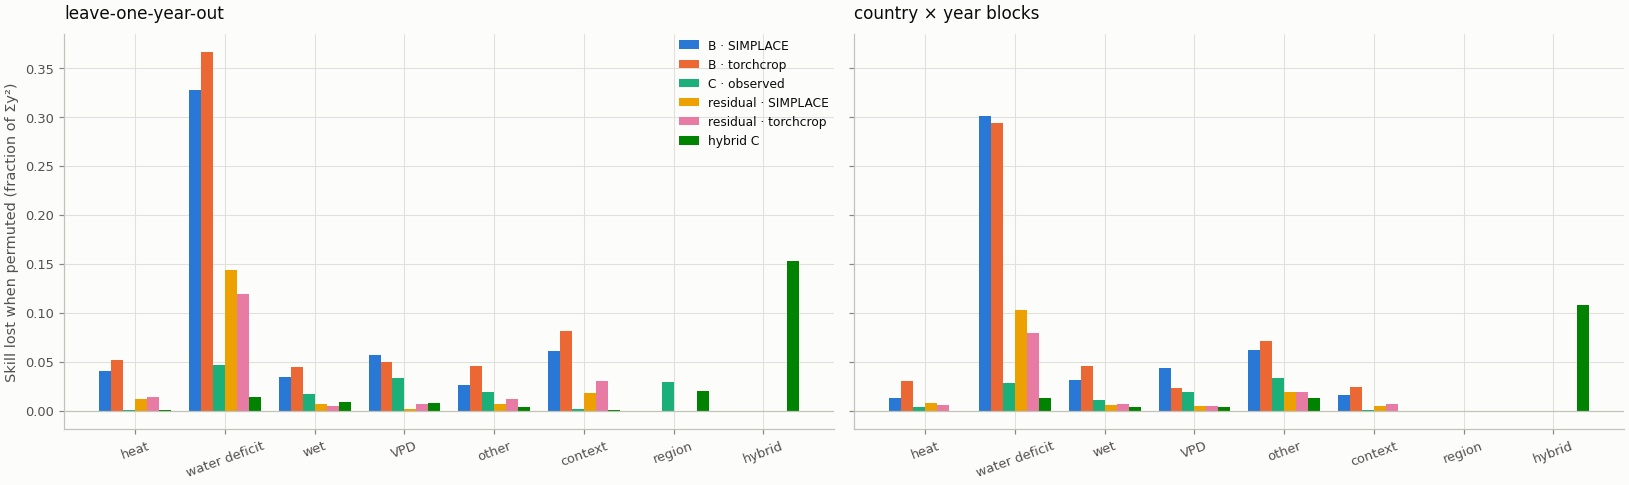

In [13]:
best_structure = (structure_table[(structure_table["scheme"] == "leave-one-year-out")
                                  & structure_table["model"].str.startswith("C ·")]
                  .sort_values("R²").iloc[-1]["model"].split("· ", 1)[1])
kind = STRUCTURES[best_structure]
print(f"best structure for C: {best_structure}")
final_specs = [
    dg.Spec("B · SIMPLACE", "simplace", best_features),
    dg.Spec("B · torchcrop", "torchcrop", best_features),
    dg.Spec("C · observed", "observed", best_features, model=kind),
    dg.Spec("residual · SIMPLACE", "residual:simplace", best_features),
    dg.Spec("residual · torchcrop", "residual:torchcrop", best_features),
    dg.Spec("hybrid C", "observed", best_features, hybrid=True, model=kind),
]
final = {scheme: dg.run_specs(best_panel, final_specs, folds[scheme], scheme, n_repeats=3) for scheme in folds}
final_table = pd.DataFrame([{"scheme": scheme, "model": n, **r.scores()}
                            for scheme, res in final.items() for n, r in res.items()])
importance = pd.concat({scheme: pd.DataFrame({n: r.importance() for n, r in res.items()}).T
                        for scheme, res in final.items()}, names=["scheme", "model"])
importance = importance.reindex(columns=[g for g in dg.IMPORTANCE_ORDER if g in importance])
importance.to_csv(TABLES / "final_grouped_importance.csv")

fig, axes = plt.subplots(1, 2, figsize=(15.0, 4.6), sharey=True)
for ax, scheme in zip(axes, folds):
    imp = importance.loc[scheme]
    width = 0.8 / len(imp)
    for i, name in enumerate(imp.index):
        ax.bar(np.arange(imp.shape[1]) + i * width, imp.loc[name].fillna(0), width, label=name)
    ax.set_xticks(np.arange(imp.shape[1]) + 0.4 - width / 2, imp.columns, rotation=20)
    ax.axhline(0, color=PALETTE["baseline"], lw=0.8)
    ax.set_title(scheme)
axes[0].set_ylabel("Skill lost when permuted (fraction of Σy²)")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
save(fig, "final_importance", FIGURES)
importance.round(3)

## Step 5 — Residual forensics

These are the leave-one-year-out residuals (observed − predicted) of the best C
model, of the hybrid, and of torchcrop scored directly against the
observations (rescaled in-fold, Step 2). A miss common to all three is a
season that neither the indices nor the crop model explain.

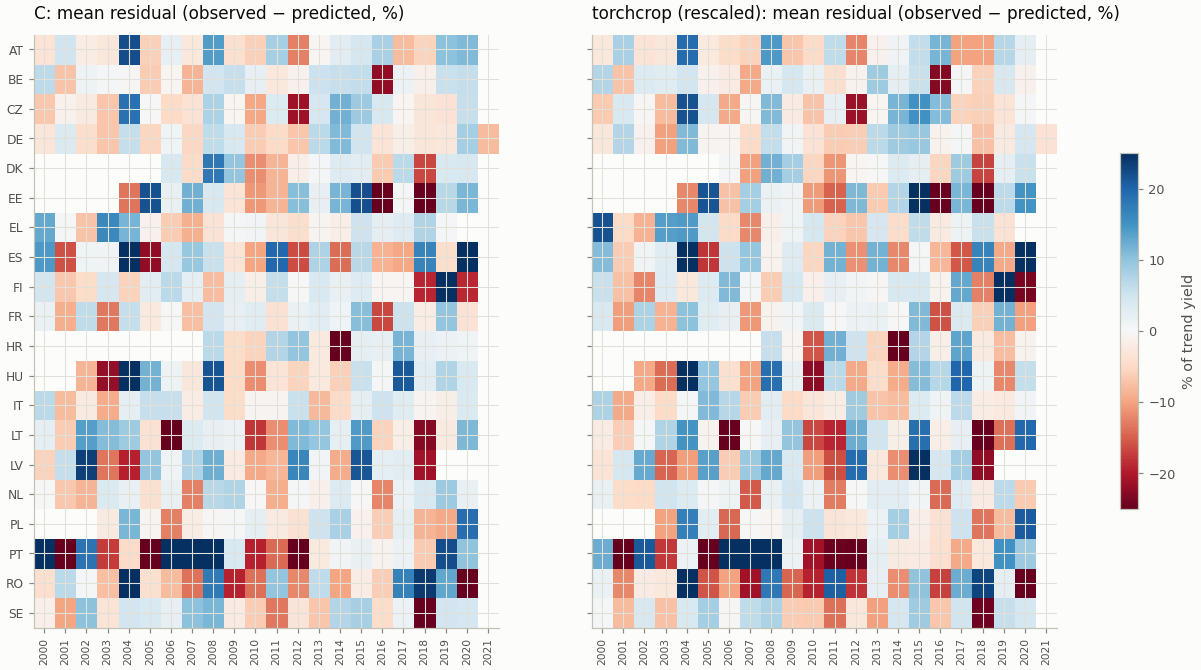

In [14]:
forensic = dg.residual_frame(best_panel, {
    "C": final["leave-one-year-out"]["C · observed"],
    "hybrid": final["leave-one-year-out"]["hybrid C"],
    "torchcrop (rescaled)": step2["leave-one-year-out"]["torchcrop vs observed (rescaled)"],
})
forensic.to_csv(TABLES / "step5_residuals.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(15.0, 7.0), sharey=True)
for ax, name in zip(axes, ("C", "torchcrop (rescaled)")):
    grid = forensic.pivot_table(index="country", columns="year", values=f"resid · {name}", aggfunc="mean")
    im = ax.imshow(grid.to_numpy(), cmap="RdBu", vmin=-25, vmax=25, aspect="auto")
    ax.set_xticks(range(grid.shape[1]), grid.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(grid.shape[0]), grid.index, fontsize=8)
    ax.set_title(f"{name}: mean residual (observed − predicted, %)")
fig.colorbar(im, ax=axes, shrink=0.6, label="% of trend yield")
save(fig, "step5_residual_country_year", FIGURES);

Unit residuals in the three best-known seasons; red means the observed yield was below the prediction:

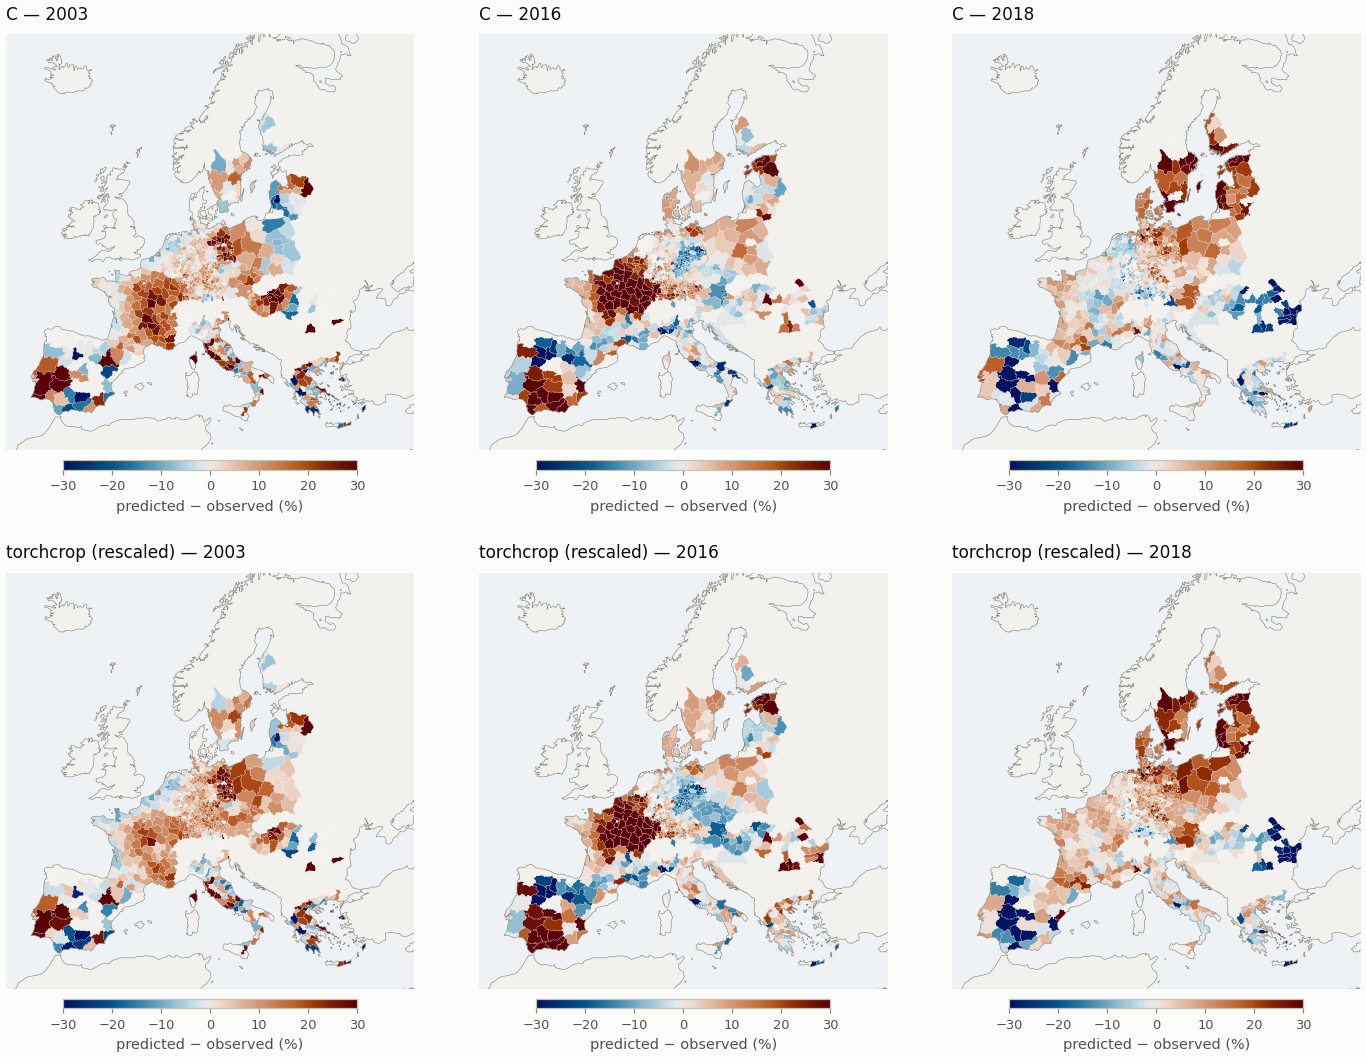

In [15]:
polygons = load_admin_polygons(countries)
fig, axes = plt.subplots(2, 3, figsize=(13.2, 10.0), subplot_kw={"projection": EUROPE_PROJECTION})
for r, name in enumerate(("C", "torchcrop (rescaled)")):
    for c, year in enumerate((2003, 2016, 2018)):
        vals = forensic[forensic["year"] == year].set_index("adm_id")[f"resid · {name}"]
        country_choropleth(polygons, -vals, key_col="adm_id", diverging=True, vmax=30, linewidth=0.1,
                           title=f"{name} — {year}", cbar_label="predicted − observed (%)", ax=axes[r, c])
fig.tight_layout()
save(fig, "step5_event_maps", FIGURES);

The largest misses, as country-seasons with at least three units. Each is
listed with the three stage indices furthest from their normal (per-unit
z-score) and any documented event. A miss whose anomalous indices are all
wetness, radiation or sequence terms points to a process none of the models
represent, such as disease, lodging or harvest losses.

In [16]:
stage_cols = [c for c in best_panel if c.startswith(dg.STAGE_PREFIX)]
stage_z = best_panel[["country", "year"]].join(
    best_panel.groupby("adm_id")[stage_cols].transform(lambda x: (x - x.mean()) / x.std()))
for name in ("C", "torchcrop (rescaled)"):
    print(f"\n=== {name}")
    misses = dg.top_misses(forensic, f"resid · {name}", stage_z)
    misses.to_csv(TABLES / f"step5_top_misses_{name.split()[0]}.csv")
    display(misses.round(1))


=== C


units  observed anomaly (%)  mean residual (%)  \
country year                                                   
PT      2012      5                 -42.3              -36.7   
        2005      5                 -42.6              -36.2   
        2001      5                 -28.7              -30.1   
EE      2018      5                 -39.9              -29.4   
SE      2018     14                 -40.6              -28.7   
RO      2020     23                 -35.9              -27.5   
EE      2016      5                 -31.0              -26.8   
LT      2006     10                 -37.3              -25.2   
        2018      9                 -31.0              -22.8   
ES      2005     26                 -36.7              -22.2   
BE      2016     11                 -26.7              -22.1   
HU      2003     20                 -39.0              -22.0   
CZ      2012     14                 -22.6              -21.1   
LV      2018      5                 -26.1              -21.0   
        2004      5                 -10.1              -19.5   

                               most anomalous stage indices (z)  \
country year                                                      
PT      2012  vpd_winter +2.2, cdd_winter +2.2, rad_winter +2.0   
        2005   frost_stem +2.8, sm_winter -2.6, cdd_winter +2.3   
        2001  prec_autumn +2.2, cwb_autumn +2.2, wet_autumn ...   
EE      2018        vpd_stem +2.4, rad_stem +2.2, cwb_stem -2.2   
SE      2018  edd_grainfill +3.5, vpd_grainfill +3.1, vpd_st...   
RO      2020  tmax_winter +2.0, vpd_winter +1.9, tmean_winte...   
EE      2016  sm_winter -2.7, cdd_autumn +2.1, waterlog_wint...   
LT      2006  vpd_grainfill +2.0, cdd_grainfill +1.9, cwb_au...   
        2018  waterlog_autumn +2.7, rad_stem +2.4, prec_autu...   
ES      2005  frost_winter +2.9, frost_stem +2.3, tmean_wint...   
BE      2016  waterlog_grainfill +3.5, prec_flowering +2.7, ...   
HU      2003  edd_stem +3.1, frost_stem +2.0, frost_winter +1.7   
CZ      2012    winterkill +2.9, cdd_winter +1.4, edd_stem +1.3   
LV      2018  waterlog_autumn +3.3, vpd_stem +2.2, rad_stem ...   
        2004  prec_flowering +1.7, cwb_flowering +1.7, rad_f...   

                                                candidate event  
country year                                                     
PT      2012                               2012 Iberian drought  
        2005                               2005 Iberian drought  
        2001                                                  —  
EE      2018                     2018 northern drought and heat  
SE      2018                     2018 northern drought and heat  
RO      2020                              2020 Romanian drought  
EE      2016                                                  —  
LT      2006                                                  —  
        2018                     2018 northern drought and heat  
ES      2005                               2005 Iberian drought  
BE      2016  2016 wet, dull spring and early summer (diseas...  
HU      2003                          2003 heatwave and drought  
CZ      2012                                                  —  
LV      2018                     2018 northern drought and heat  
        2004                                                  —


=== torchcrop (rescaled)


units  observed anomaly (%)  mean residual (%)  \
country year                                                   
PT      2012      5                 -42.3              -36.9   
RO      2020     23                 -35.9              -30.7   
PT      2005      5                 -42.6              -30.0   
LT      2018      9                 -31.0              -28.1   
EE      2016      5                 -31.0              -28.0   
LT      2006     10                 -37.3              -27.7   
EE      2018      5                 -39.9              -27.6   
PT      2001      5                 -28.7              -25.0   
        2011      5                 -21.3              -24.5   
SE      2018     14                 -40.6              -24.3   
FI      2020      6                 -19.7              -23.8   
BE      2016     11                 -26.7              -23.0   
HU      2010     16                 -12.9              -22.3   
LV      2018      5                 -26.1              -22.2   
CZ      2012     14                 -22.6              -21.5   

                               most anomalous stage indices (z)  \
country year                                                      
PT      2012  vpd_winter +2.2, cdd_winter +2.2, rad_winter +2.0   
RO      2020  tmax_winter +2.0, vpd_winter +1.9, tmean_winte...   
PT      2005   frost_stem +2.8, sm_winter -2.6, cdd_winter +2.3   
LT      2018  waterlog_autumn +2.7, rad_stem +2.4, prec_autu...   
EE      2016  sm_winter -2.7, cdd_autumn +2.1, waterlog_wint...   
LT      2006  vpd_grainfill +2.0, cdd_grainfill +1.9, cwb_au...   
EE      2018        vpd_stem +2.4, rad_stem +2.2, cwb_stem -2.2   
PT      2001  prec_autumn +2.2, cwb_autumn +2.2, wet_autumn ...   
        2011  edd_stem +3.9, tmean_stem +1.9, wet_flowering ...   
SE      2018  edd_grainfill +3.5, vpd_grainfill +3.1, vpd_st...   
FI      2020   edd_stem +3.0, cwb_winter +1.9, prec_winter +1.9   
BE      2016  waterlog_grainfill +3.5, prec_flowering +2.7, ...   
HU      2010  waterlog_flowering +3.5, waterlog_grainfill +3...   
LV      2018  waterlog_autumn +3.3, vpd_stem +2.2, rad_stem ...   
CZ      2012    winterkill +2.9, cdd_winter +1.4, edd_stem +1.3   

                                                candidate event  
country year                                                     
PT      2012                               2012 Iberian drought  
RO      2020                              2020 Romanian drought  
PT      2005                               2005 Iberian drought  
LT      2018                     2018 northern drought and heat  
EE      2016                                                  —  
LT      2006                                                  —  
EE      2018                     2018 northern drought and heat  
PT      2001                                                  —  
        2011                                                  —  
SE      2018                     2018 northern drought and heat  
FI      2020                                                  —  
BE      2016  2016 wet, dull spring and early summer (diseas...  
HU      2010                                                  —  
LV      2018                     2018 northern drought and heat  
CZ      2012                                                  —

What the residuals still track: the Spearman correlation of each residual
with every stage index (z-scored per unit), pooled over unit-seasons. These
are the indices with the largest |ρ|.

In [17]:
corr = pd.DataFrame({name: [forensic[f"resid · {name}"].corr(stage_z[c], method="spearman") for c in stage_cols]
                     for name in ("C", "hybrid", "torchcrop (rescaled)")}, index=[c[len(dg.STAGE_PREFIX):] for c in stage_cols])
corr.to_csv(TABLES / "step5_residual_correlations.csv")
corr.reindex(corr.abs().max(axis=1).sort_values(ascending=False).index).head(15).round(3)

,C,hybrid,torchcrop (rescaled)
frost_grainfill,0.210,0.164,0.257
frost_flowering,-0.185,-0.222,-0.111
winterkill,-0.154,-0.135,-0.163
tmean_stem,-0.026,-0.014,-0.157
tmean_flowering,-0.111,-0.100,-0.150
vpd_stem,-0.030,-0.036,-0.146
tmax_stem,-0.013,-0.010,-0.143
waterlog_grainfill,-0.072,-0.065,-0.138
tmax_flowering,-0.090,-0.082,-0.123
rad_stem,-0.037,-0.062,-0.120


## Synthesis

### 1. Every baseline and ablation, one table

The same panel, anomalies and folds throughout. R² is pooled, fold mean ± sd
is given alongside, and RMSE is in % of trend yield.

In [18]:
master = pd.concat([
    table.assign(block="Step 2 · baseline").rename(columns={"baseline": "model"}),
    ablation_table.assign(block="Step 3 · ablation", model=lambda f: f["ablation"] + " → " + f["target"]),
    structure_table.assign(block="Step 4 · structure"),
    final_table.assign(block="final · best setup"),
], ignore_index=True)[["block", "model", "scheme", "R²", "R² fold mean", "R² fold sd", "RMSE (%)", "rows"]]
master.to_csv(TABLES / "master_table.csv", index=False)
(master.assign(cell=lambda f: f.apply(lambda r: f"{r['R²']:.3f} ({r['R² fold mean']:.2f}±{r['R² fold sd']:.2f}) | {r['RMSE (%)']:.1f}", axis=1))
 .pivot_table(index=["block", "model"], columns="scheme", values="cell", aggfunc="first", sort=False))

scheme                                                      leave-one-year-out  \
block              model                                                         
Step 2 · baseline  B · SIMPLACE (ML)                  0.246 (0.21±0.15) | 14.8   
                   B · torchcrop (ML)                 0.323 (0.26±0.23) | 11.2   
                   SIMPLACE vs observed (no ML)     -0.323 (-0.60±0.55) | 19.7   
                   torchcrop vs observed (no ML)    -0.124 (-0.23±0.30) | 18.1   
                   SIMPLACE vs observed (rescaled)    0.110 (0.09±0.13) | 16.1   
...                                                                        ...   
final · best setup B · torchcrop                       0.469 (0.42±0.21) | 9.9   
                   C · observed                       0.131 (0.11±0.09) | 15.9   
                   residual · SIMPLACE                0.122 (0.13±0.18) | 18.4   
                   residual · torchcrop               0.099 (0.11±0.10) | 17.2   
                   hybrid C                           0.183 (0.17±0.12) | 15.5   

scheme                                                   country × year blocks  
block              model                                                        
Step 2 · baseline  B · SIMPLACE (ML)                  0.157 (0.14±0.21) | 16.2  
                   B · torchcrop (ML)                 0.179 (0.08±0.52) | 12.8  
                   SIMPLACE vs observed (no ML)     -0.296 (-0.64±0.63) | 21.8  
                   torchcrop vs observed (no ML)    -0.139 (-0.35±0.55) | 20.4  
                   SIMPLACE vs observed (rescaled)    0.078 (0.05±0.14) | 18.4  
...                                                                        ...  
final · best setup B · torchcrop                      0.273 (0.15±0.70) | 12.0  
                   C · observed                       0.057 (0.07±0.13) | 18.6  
                   residual · SIMPLACE                0.076 (0.11±0.17) | 21.0  
                   residual · torchcrop               0.041 (0.05±0.21) | 20.0  
                   hybrid C                           0.094 (0.11±0.16) | 18.2  

[82 rows x 2 columns]

### 2. Grouped importance, side by side

These are the final-run values from above. Leave-one-year-out comes first,
then country × year blocks.

In [19]:
importance.round(3)

heat  water deficit    wet  \
scheme                model                                               
leave-one-year-out    B · SIMPLACE          0.041          0.327  0.035   
                      B · torchcrop         0.052          0.366  0.045   
                      C · observed          0.001          0.046  0.017   
                      residual · SIMPLACE   0.012          0.144  0.007   
                      residual · torchcrop  0.014          0.119  0.005   
                      hybrid C              0.001          0.014  0.009   
country × year blocks B · SIMPLACE          0.013          0.301  0.032   
                      B · torchcrop         0.030          0.294  0.045   
                      C · observed          0.004          0.028  0.011   
                      residual · SIMPLACE   0.008          0.102  0.006   
                      residual · torchcrop  0.006          0.079  0.007   
                      hybrid C             -0.001          0.013  0.004   

                                              VPD  other  context  region  \
scheme                model                                                 
leave-one-year-out    B · SIMPLACE          0.057  0.026    0.061     NaN   
                      B · torchcrop         0.050  0.046    0.082     NaN   
                      C · observed          0.033  0.020    0.001   0.029   
                      residual · SIMPLACE   0.002  0.007    0.018     NaN   
                      residual · torchcrop  0.007  0.012    0.031     NaN   
                      hybrid C              0.007  0.004    0.001   0.020   
country × year blocks B · SIMPLACE          0.044  0.062    0.016     NaN   
                      B · torchcrop         0.023  0.071    0.025     NaN   
                      C · observed          0.019  0.033    0.000   0.000   
                      residual · SIMPLACE   0.005  0.019    0.005     NaN   
                      residual · torchcrop  0.004  0.019    0.007     NaN   
                      hybrid C              0.004  0.013   -0.000   0.000   

                                            hybrid  
scheme                model                         
leave-one-year-out    B · SIMPLACE             NaN  
                      B · torchcrop            NaN  
                      C · observed             NaN  
                      residual · SIMPLACE      NaN  
                      residual · torchcrop     NaN  
                      hybrid C               0.153  
country × year blocks B · SIMPLACE             NaN  
                      B · torchcrop            NaN  
                      C · observed             NaN  
                      residual · SIMPLACE      NaN  
                      residual · torchcrop     NaN  
                      hybrid C               0.108

### 3. Decomposing the R²(B) − R²(C) gap

All values are under leave-one-year-out, with B = torchcrop. Each component is
a difference of two rows of the master table, so each can be traced:

| Component | Measured as |
|---|---|
| (i) anomaly / detrending inconsistency | gap(linear, in-fold) − gap(best detrending, in-fold), Step 1 |
| (ii) leakage | gap(full-series references) − gap(in-fold references), Step 1; plus R²(C) under leave-one-country-out − under country × year blocks, which is the leak that scheme would add |
| (iii) missing or misaligned features | R²(C, best features + structure) − R²(C, S0 pooled) — *recovered*; and R²(hybrid) − R²(C best) — signal the crop models still extract from the same weather that the indices do not |
| (iv) processes the crop model lacks | R²(hybrid) − R²(torchcrop rescaled) — what the indices add on top of the crop model |
| (v) non-weather noise | 1 − R²(best observed model) — an upper bound: it also contains any weather signal no approach here extracted |

In [20]:
def a(target, method, cv):
    return float(audit[(audit["target"] == dg.TARGETS[target]) & (audit["detrending"] == method)
                       & (audit["cv"] == cv)]["R²"].iloc[0])

LOYO_IN, LOYO_FULL = "leave-one-year-out (in-fold refs)", "leave-one-year-out (full-series refs)"
gap = lambda method, cv: a("torchcrop", method, cv) - a("observed", method, cv)
best_det = max(dg.DETRENDS, key=lambda m: a("observed", m, LOYO_IN))
loyo = lambda frame, col, name: float(frame[(frame["scheme"] == "leave-one-year-out") & (frame[col] == name)]["R²"].iloc[0])
s0_c = float(ablation_table[(ablation_table["scheme"] == "leave-one-year-out") & (ablation_table["target"] == "C")
                            & (ablation_table["ablation"] == "S0 · 12 season indices")]["R²"].iloc[0])
c_best = loyo(final_table, "model", "C · observed")
hybrid_best = loyo(final_table, "model", "hybrid C")
crop_scaled = loyo(table, "baseline", "torchcrop vs observed (rescaled)")
b_best = loyo(final_table, "model", "B · torchcrop")
loco_c = a("observed", "linear", "leave-one-country-out")
blocked_c = float(table[(table["scheme"] == "country × year blocks") & (table["baseline"] == "C · observed (ML)")]["R²"].iloc[0])

decomposition = pd.Series({
    "gap, original setup (linear, full-series references)": gap("linear", LOYO_FULL),
    "gap, final setup (B best − C best)": b_best - c_best,
    "(i) detrending inconsistency": gap("linear", LOYO_IN) - gap(best_det, LOYO_IN),
    "(ii) leakage: full-series vs in-fold references": gap("linear", LOYO_FULL) - gap("linear", LOYO_IN),
    "(ii) leakage leave-one-country-out would add to R²(C)": loco_c - blocked_c,
    "(iii) recovered by features + structure (ΔR²(C))": c_best - s0_c,
    "(iii) still extracted only by the crop models (hybrid − C)": hybrid_best - c_best,
    "(iv) indices add beyond the crop model (hybrid − crop rescaled)": hybrid_best - crop_scaled,
    "(v) unexplained in the best observed model (1 − R²)": 1 - max(c_best, hybrid_best),
}).round(3).rename("R² units")
decomposition.to_csv(TABLES / "gap_decomposition.csv")
decomposition

gap, original setup (linear, full-series references)               0.312
gap, final setup (B best − C best)                                 0.338
(i) detrending inconsistency                                       0.033
(ii) leakage: full-series vs in-fold references                    0.000
(ii) leakage leave-one-country-out would add to R²(C)              0.057
(iii) recovered by features + structure (ΔR²(C))                   0.086
(iii) still extracted only by the crop models (hybrid − C)         0.052
(iv) indices add beyond the crop model (hybrid − crop rescaled)    0.085
(v) unexplained in the best observed model (1 − R²)                0.817
Name: R² units, dtype: float64

In [21]:
d = decomposition
print(f"R²(B torchcrop) − R²(C) was {d.iloc[0]:+.3f} in the original setup and is {d.iloc[1]:+.3f} after Steps 1–4.")
dc = a("observed", best_det, LOYO_IN) - a("observed", "linear", LOYO_IN)
db = a("torchcrop", best_det, LOYO_IN) - a("torchcrop", "linear", LOYO_IN)
print(f"(i)  {best_det} instead of linear detrending moves the gap by {d.iloc[2]:+.3f}: "
      f"R²(C) {dc:+.3f}, R²(B) {db:+.3f}.")
effect = ("no effect" if abs(d.iloc[3]) < 0.01 else
          "they deflated rather than inflated skill" if d.iloc[3] < 0 else "they inflated the gap")
print(f"(ii) Full-series references changed the gap by {d.iloc[3]:+.3f} ({effect}); "
      f"leave-one-country-out would have added {d.iloc[4]:+.3f} to R²(C) through same-season leakage.")
print(f"(iii) Better features and structure recovered {d.iloc[5]:+.3f} R² for C; the crop models still extract "
      f"{d.iloc[6]:+.3f} that the indices miss.")
print(f"(iv) On top of the crop model, the indices add {d.iloc[7]:+.3f}: the signal of processes it lacks.")
print(f"(v) {d.iloc[8]:.0%} of the observed anomaly variance remains unexplained by the best observed model; "
      "this bounds the non-weather noise from above.")

R²(B torchcrop) − R²(C) was +0.312 in the original setup and is +0.338 after Steps 1–4.
(i)  loess instead of linear detrending moves the gap by +0.033: R²(C) +0.012, R²(B) -0.021.
(ii) Full-series references changed the gap by +0.000 (no effect); leave-one-country-out would have added +0.057 to R²(C) through same-season leakage.
(iii) Better features and structure recovered +0.086 R² for C; the crop models still extract +0.052 that the indices miss.
(iv) On top of the crop model, the indices add +0.085: the signal of processes it lacks.
(v) 82% of the observed anomaly variance remains unexplained by the best observed model; this bounds the non-weather noise from above.
